In [5]:
from skyfield.api import load, wgs84
import numpy as np
from numpy import array2string
from datetime import datetime, timedelta
import os
from scipy import io as sio
import pytz
import math
import scipy.io


In [6]:
# TODO: define constants and set other parameters
c = 299792458.0 # speed of light in m/s
fc = 11.575e9 # carrier frequency in Hz
f = 0.2e6 # narrowband tone freq in Hz
lo = 9.75e9 # local oscillator frequency in Hz
fs = 1e2 # sampling frequency in Hz
lam = c/fc # wavelength in m
d = lam/2 # antenna spacing in m
re = 6378e3 # earth radius in m
min_elevation = 60 # minimum elevation of visible sats


In [29]:
# Load tle from path

# change the path
path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
# path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\10_31\\STARLINK-6150.tle'

satellites = load.tle_file(path)
print(satellites)

# % assume we have 4 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB4 |       W + E
# | LNB1 LNB3 |         S
#  ------------
# initialize location of 4 LNBs with lat, lon = +40.11389690596162, -88.22484814695467 (UIUC)

lat_1, lon_1 = +40.11389690596162, -88.22484814695467
lnb_1 = wgs84.latlon(lat_1, lon_1)
lnb_2 = wgs84.latlon(lat_1+np.rad2deg(d/re), lon_1)
lnb_3 = wgs84.latlon(lat_1, lon_1-np.rad2deg(d/re)/np.cos(np.deg2rad(lat_1)))
lnb_4 = wgs84.latlon(lat_1+np.rad2deg(d/re), lon_1-np.rad2deg(d/re)/np.cos(np.deg2rad(lat_1)))
lnbs = [lnb_1, lnb_2, lnb_3, lnb_4]

# set start time and stop time, add 5 hours to account for time zone difference
ts = load.timescale()
start_time = datetime(2023, 10, 30, 23, 55, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 10, 31, 0, 5, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

[<EarthSatellite STARLINK-6150 catalog #57119 epoch 2023-10-31 06:43:42 UTC>]


The following section tries to estimate the AoA (both azimuth & elevation) using MUSIC.

Assume that the satellite is transmitting at frequency $f_c+f=11.575 GHz+0.2 MHz$, i.e.,
$$y(t) = \exp(j2\pi(f+f_c)t),$$
where $f_c$ is the carrier frequency and $f$ is the narrowband tone's frequency.

Assume when it arrives at LNB-1 at UIUC, it becomes 
$$y_1(t) = A\exp(j2\pi(f+f_c)t)+n_1,$$
where $A$ is path loss, $n_1$ is the noise at LNB-1.

Similarly, for LNB-i (i=2,3,4), there will be time delays since the distance between LNB-i will be different from LNB-1, given by
$$y_i(t) = A\exp(j2\pi(f+f_c)\times (t-(r_i-r_1)/c))+n_i, \\
 = A\exp(-j2\pi(f+f_c)*(r_i-r_1)/c)\times \exp(j2\pi(f+f_c)t)+n_i, \\
 = A'\exp(j2\pi(f+f_c)t)+n_i,$$
where $r_i$ is the distance between the sat and the i-th LNB. If $r_i>r_1$ then it arrives later. Also assume that $A$ is same for different LNBs since they are very close to each other.

$y_i(t)$ is in anaglog domain, then LNB \& USRP down-converts it at sample it. In the most ideal case where we have synchronized LNBs and USRPs, the digital signal we get is removing $f_c$ and substituting continuous time $t$ with discrete time samples $n*T_s = n/F_s$, i.e.,
$$y_i[n] = A'\exp(j2\pi f n/f_s)+n_i,$$
from where we start our simulation

In [72]:
# get start time as ts.utc
t = ts.utc(start_time)
n = np.arange(0, fs*60*10, 1)
i = 0
received_sig_1 = np.empty(len(n), dtype=complex)
received_sig_2 = np.empty(len(n), dtype=complex)
received_sig_3 = np.empty(len(n), dtype=complex)
received_sig_4 = np.empty(len(n), dtype=complex)
d1 = np.empty(len(n))
d2 = np.empty(len(n))
d3 = np.empty(len(n))
d4 = np.empty(len(n))
# array to record elevation and azimuth of satellite from 4 lnbs
el_gt = np.empty(len(n))
az_gt = np.empty(len(n))
while True:
    dist1 = (satellites[0]-lnb_1).at(t)
    el1, az1, distance1 = dist1.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el1.degrees, az1.degrees)
    _, _, the_range1, _, _, range_rate1 = dist1.frame_latlon_and_rates(lnb_1)
    doppler_shift1 = (fc)*range_rate1.km_per_s*1000/c

    dist2 = (satellites[0]-lnb_2).at(t)
    el2, az2, distance2 = dist2.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el2.degrees, az2.degrees)
    _, _, the_range2, _, _, range_rate2 = dist2.frame_latlon_and_rates(lnb_2)
    doppler_shift2 = (fc)*range_rate2.km_per_s*1000/c

    dist3 = (satellites[0]-lnb_3).at(t)
    el3, az3, distance3 = dist3.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el3.degrees, az3.degrees)
    _, _, the_range3, _, _, range_rate3 = dist3.frame_latlon_and_rates(lnb_3)
    doppler_shift3 = (fc)*range_rate3.km_per_s*1000/c

    dist4 = (satellites[0]-lnb_4).at(t)
    el4, az4, distance4 = dist4.altaz()
    # print time, elevation, azimuth, latitude, longitude
    print(t.utc_iso(), el4.degrees, az4.degrees)
    _, _, the_range4, _, _, range_rate4 = dist4.frame_latlon_and_rates(lnb_4)
    doppler_shift4 = (fc)*range_rate4.km_per_s*1000/c

    # print(doppler_shift1, doppler_shift2, doppler_shift3, doppler_shift4)
    # print(the_range1.km, the_range2.km, the_range3.km, the_range4.km)
    # generate received signal TODO: double check
    # received_sig_0 = np.exp(-1j*2*np.pi*(fc+f+doppler_shift)*(n[i]/fs+the_range.km/c)) # TODO: can comment this out
    # downconvert to baseband : for now we assume that the effect of doppler shift is equivalent on all lnbs and will cancel out when calculating phase difference
    # TODO: add effect of doppler shift

    received_sig_1[i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range1.km/c*1000.0) 
    received_sig_2[i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range2.km/c*1000.0)
    received_sig_3[i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range3.km/c*1000.0)
    received_sig_4[i] = np.exp(-1j*2*np.pi*(f)*n[i]/fs)*np.exp(1j*2*np.pi*(fc+f)*the_range4.km/c*1000.0)
    d1[i] = the_range1.km
    d2[i] = the_range2.km
    d3[i] = the_range3.km
    d4[i] = the_range4.km
    el_gt[i] = float(el1.degrees)
    az_gt[i] = float(az1.degrees)
    # plot phase difference between received signals
    

    # TODO: replicate code for more antennas

    # TODO: get phase difference between antennas

    #TODO: get AoA

    # increment t which is ts.utc by 1 second
    t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs)) # TODO: fix this
    i += 1
    print(i)

    if t.utc_datetime() >= stop_time:
        break


2023-10-31T04:55:00Z 4.623830910045632 287.4495182092127
2023-10-31T04:55:00Z 4.623830952798872 287.4495178886922
2023-10-31T04:55:00Z 4.623831046158066 287.4495182123373
2023-10-31T04:55:00Z 4.623831088911307 287.4495178918167
1
2023-10-31T04:55:00Z 4.6245603395672665 287.44954804065037
2023-10-31T04:55:00Z 4.624560382322065 287.4495477201191
2023-10-31T04:55:00Z 4.624560475684363 287.4495480437785
2023-10-31T04:55:00Z 4.624560518439154 287.4495477232472
2
2023-10-31T04:55:00Z 4.62528979418252 287.4495778720499
2023-10-31T04:55:00Z 4.62528983693884 287.4495775515078
2023-10-31T04:55:00Z 4.625289930304275 287.44957787518155
2023-10-31T04:55:00Z 4.6252899730606 287.4495775546395
3
2023-10-31T04:55:00Z 4.626019273888144 287.4496077034112
2023-10-31T04:55:00Z 4.626019316646004 287.44960738285835
2023-10-31T04:55:00Z 4.62601941001458 287.44960770654643
2023-10-31T04:55:00Z 4.626019452772439 287.4496073859936
4
2023-10-31T04:55:00Z 4.626748778688935 287.4496375347343
2023-10-31T04:55:00Z 4.

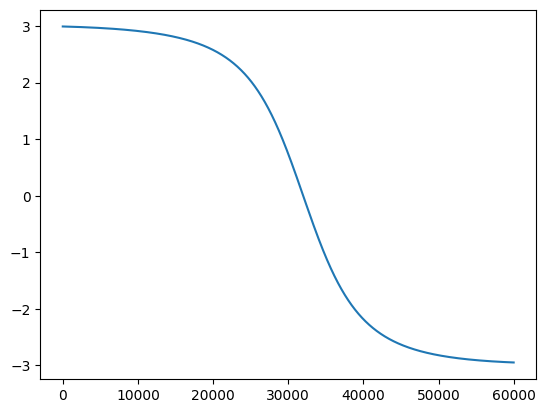

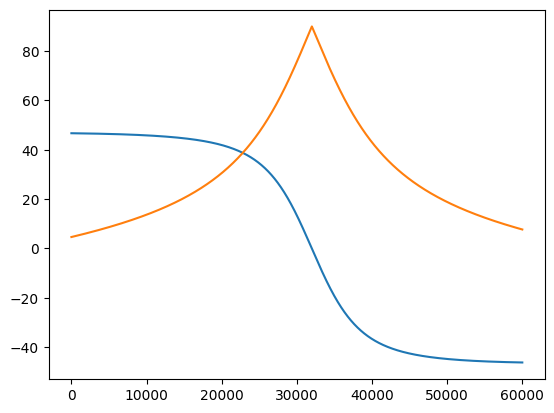

In [80]:
# plotting the phase difference between received signals
import matplotlib.pyplot as plt
from numpy import arccos
del_phi = np.unwrap(np.angle(received_sig_1/received_sig_3))
plt.plot(del_phi)
plt.figure()
# plot angle of arrival 
plt.plot(90-np.abs(np.degrees(np.sin(del_phi*lam/(2*np.pi*d)))-90))
plt.plot((el_gt))

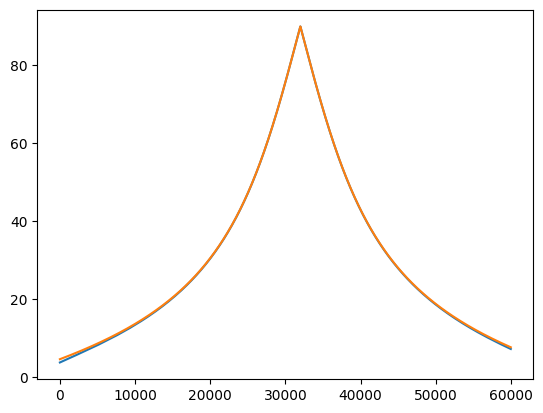

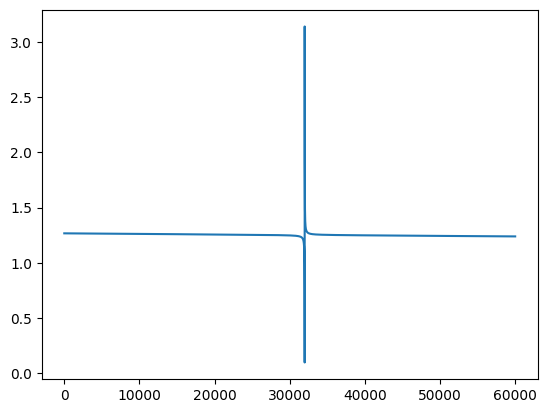

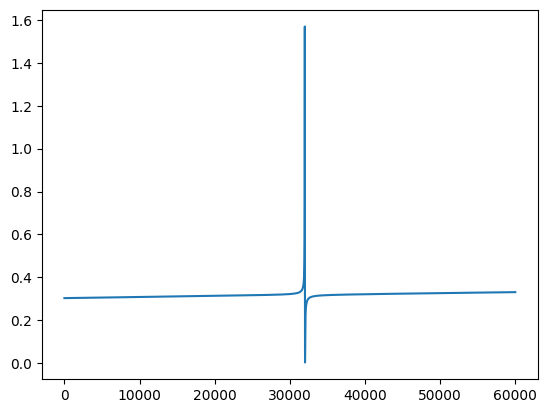

In [188]:
del_phi_1 = np.unwrap(np.angle(received_sig_1/received_sig_2))
del_phi_2 = np.unwrap(np.angle(received_sig_1/received_sig_3))


a = (np.arctan(del_phi_1/del_phi_2))
el = np.arccos(del_phi_1*lam/(2*np.pi*d*np.sin(a))) 

az = np.empty(len(a))
az_1 = np.empty(len(a))
az_2 = np.empty(len(a))
for i in range(len(a)):
    az_1[i] = (np.arccos(del_phi_1[i]*lam/(2*np.pi*d*np.cos(el[i]))))
    az_2[i] = (np.arccos(del_phi_2[i]*lam/(2*np.pi*d*np.cos(el[i]))))
    # if az_1[i] > 0 and az_2[i] > 0:
    #     az[i] = 270+np.degrees(a[i])
    #     if az[i] > 360:
    #         az[i] = 90+np.degrees(a[i])
    # elif az_1[i] > 0 and az_2[i] < 0:
    #     az[i] = 90+np.degrees(a[i])
    # elif az_1[i] < 0 and az_2[i] > 0:
    #     az[i] = 90+np.degrees(a[i])


plt.figure()
plt.plot(90-np.abs(90-np.degrees(el)))
plt.plot(el_gt)

plt.figure()
plt.plot((az_1))
plt.figure()
plt.plot((az_2))

In [41]:
my_var = {'rx1_': received_sig_1, 'rx2_': received_sig_2, 'rx3_': received_sig_3, 'rx4_': received_sig_4}
scipy.io.savemat('my_file_.mat', {'my_var_new': my_var})

In [ ]:
dist = {'d1': d1, 'd2': d2, 'd3': d3, 'd4': d4}
scipy.io.savemat('dist.mat', {'dist': dist})

In [183]:
min(az_2)

0.001471331531703789

In [186]:
for i in range(len(a)):
    print("az:", np.degrees(a[i]))
    print("az_1:", az_1[i])
    print("az_2:", az_2[i])
    print("gt:", az_gt[i])

az: 17.38514425321999
az_1: 0.2987933651580442
az_2: 0.9543178322432897
gt: 287.4495182092127
az: 17.38517002216394
az_1: 0.29879379436524256
az_2: 0.9543176978600059
gt: 287.44954804065037
az: 17.385202806432417
az_1: 0.29879434041950825
az_2: 0.9543175268920041
gt: 287.4495778720499
az: 17.385231956897663
az_1: 0.2987948259491218
az_2: 0.9543173748738067
gt: 287.4496077034112
az: 17.385263312991157
az_1: 0.29879534821555265
az_2: 0.9543172113530946
gt: 287.4496375347343
az: 17.385293891885617
az_1: 0.29879585753688653
az_2: 0.954317051885167
gt: 287.4496673660191
az: 17.385323168762724
az_1: 0.29879634517177084
az_2: 0.9543168992069624
gt: 287.44969719726583
az: 17.385353096741156
az_1: 0.2987968436513008
az_2: 0.954316743133023
gt: 287.44972702847434
az: 17.385386532427027
az_1: 0.29879740055500653
az_2: 0.954316568766136
gt: 287.4497568596446
az: 17.385410096281888
az_1: 0.29879779303375203
az_2: 0.954316445880589
gt: 287.4497866907768
az: 17.385440150649842
az_1: 0.298798293618184

In [ ]:
np.